Device: cuda

=== BASELINE ROUND-1 ATTACKS (DIGITS) ===

Digit: 0
Digit: 1
Digit: 2
Digit: 3
Digit: 4
Digit: 5
Digit: 6
Digit: 7
Digit: 8
Digit: 9


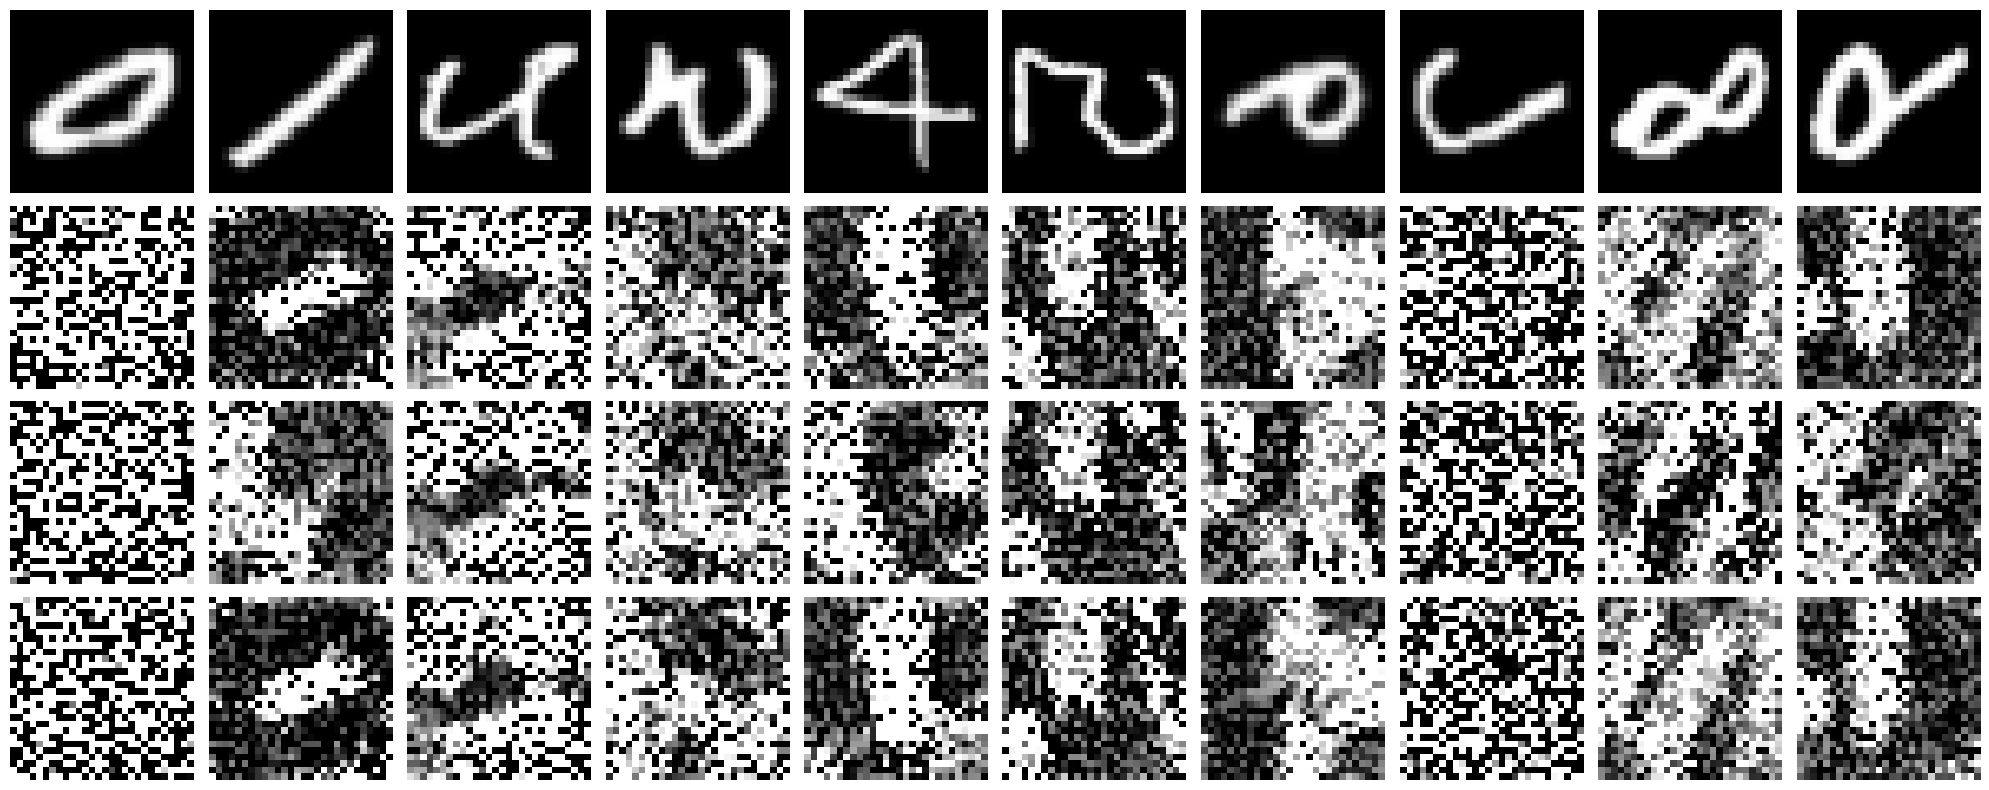

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Saved: emnist_digits_baseline_all_attacks.png


In [1]:
# ============================================================
# BASELINE FL ROUND-1 ATTACKS
# EMNIST DIGITS
# NO MASKING
# NO NOISE
# ONLY BASELINE FedProx
# Attacks: DLG + iDLG + GradInv
# FIXED: correct class-aligned reconstruction (like letters)
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import random
import copy
import matplotlib.pyplot as plt
from google.colab import files

# ============================================================
# CONFIG
# ============================================================

NUM_CLIENTS = 100
CLIENT_FRAC = 0.3

LOCAL_EPOCHS = 3
BATCH_SIZE = 128

LR = 0.01
MU = 0.01

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

SEED = 42
ALPHA = 0.1

NUM_CLASSES = 10

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

print("Device:", DEVICE)

# ============================================================
# DATASET
# ============================================================

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.EMNIST(
    root="./data",
    split="digits",
    train=True,
    download=True,
    transform=transform
)

targets = np.array(train_dataset.targets)  # already 0–9

# ============================================================
# DIRICHLET NON-IID SPLIT
# ============================================================

def dirichlet_partition(dataset, clients, alpha=0.1):

    labels = np.array(dataset.targets)
    idxs = np.arange(len(labels))

    client_dict = {i: [] for i in clients}

    class_indices = [
        idxs[labels == i] for i in range(NUM_CLASSES)
    ]

    for c_idx in class_indices:

        np.random.shuffle(c_idx)

        proportions = np.random.dirichlet(alpha * np.ones(len(clients)))
        proportions = (np.cumsum(proportions) * len(c_idx)).astype(int)
        proportions = np.concatenate(([0], proportions))

        for i, client in enumerate(clients):
            client_dict[client] += list(
                c_idx[proportions[i]:proportions[i+1]]
            )

    for client in clients:
        np.random.shuffle(client_dict[client])

    return client_dict

client_data = dirichlet_partition(
    train_dataset,
    list(range(NUM_CLIENTS)),
    alpha=ALPHA
)

# ============================================================
# MODEL
# ============================================================

class EMNIST_CNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2)

        self.fc1 = nn.Linear(64 * 7 * 7, 256)
        self.fc2 = nn.Linear(256, NUM_CLASSES)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# ============================================================
# FEDPROX LOSS
# ============================================================

def fedprox_loss(model, global_model, mu):

    prox = 0.0
    for w, w0 in zip(model.parameters(), global_model.parameters()):
        prox += torch.sum((w - w0.detach()) ** 2)

    return mu / 2 * prox

# ============================================================
# UTILS
# ============================================================

def model_to_vector(model):
    return torch.cat([p.data.view(-1) for p in model.parameters()])

def vector_to_model(model, vec):
    ptr = 0
    for p in model.parameters():
        n = p.numel()
        p.data = vec[ptr:ptr+n].view_as(p).clone()
        ptr += n

def norm_img(x):
    x = x - x.min()
    x = x / (x.max() + 1e-8)
    return x

# ============================================================
# GLOBAL MODEL
# ============================================================

global_model = EMNIST_CNN().to(DEVICE)
global_vec = model_to_vector(global_model)

# ============================================================
# CLIENT SELECTION
# ============================================================

selected_clients = random.sample(
    range(NUM_CLIENTS),
    int(NUM_CLIENTS * CLIENT_FRAC)
)

# ============================================================
# STORE
# ============================================================

updates = []
class_labels = []

digit_samples = {}

for img, y in train_dataset:

    y = int(y)

    if y not in digit_samples:
        digit_samples[y] = img

    if len(digit_samples) == NUM_CLASSES:
        break

# ============================================================
# TRAIN ROUND 1
# ============================================================

for cid in selected_clients:

    local_model = copy.deepcopy(global_model)
    local_model.train()

    optimizer = optim.SGD(
        local_model.parameters(),
        lr=LR,
        momentum=0.9,
        weight_decay=5e-4
    )

    loader = DataLoader(
        Subset(train_dataset, client_data[cid]),
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    for _ in range(LOCAL_EPOCHS):
        for x, y in loader:

            x, y = x.to(DEVICE), y.to(DEVICE)

            optimizer.zero_grad()

            out = local_model(x)

            loss = F.cross_entropy(out, y)
            loss += fedprox_loss(local_model, global_model, MU)

            loss.backward()
            optimizer.step()

    delta = model_to_vector(local_model) - global_vec
    updates.append(delta.detach().clone())

    client_labels = targets[client_data[cid]]
    class_labels.append(np.bincount(client_labels).argmax())

# ============================================================
# CLASS-CONSISTENT MAPPING (LIKE LETTERS FIX)
# ============================================================

class_updates = {}
used = set()

for i in range(len(updates)):

    label = class_labels[i]

    if label not in used:
        class_updates[label] = updates[i]
        used.add(label)

# ============================================================
# ATTACKS
# ============================================================

def dlg_attack(update, label):

    model = copy.deepcopy(global_model).to(DEVICE)
    vector_to_model(model, global_vec + update)

    x = torch.randn(1, 1, 28, 28, device=DEVICE, requires_grad=True)
    optimizer = optim.Adam([x], lr=0.1)

    y = torch.tensor([label]).to(DEVICE)

    for _ in range(200):
        optimizer.zero_grad()
        loss = F.cross_entropy(model(x), y)
        loss.backward()
        optimizer.step()
        x.data.clamp_(-1, 1)

    return x.detach()

def idlg_attack(update):

    best_img = None
    best_loss = 1e9

    for label in range(NUM_CLASSES):

        model = copy.deepcopy(global_model).to(DEVICE)
        vector_to_model(model, global_vec + update)

        x = torch.randn(1, 1, 28, 28, device=DEVICE, requires_grad=True)
        optimizer = optim.Adam([x], lr=0.1)

        y = torch.tensor([label]).to(DEVICE)

        for _ in range(100):
            optimizer.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward()
            optimizer.step()
            x.data.clamp_(-1, 1)

        if loss.item() < best_loss:
            best_loss = loss.item()
            best_img = x.detach()

    return best_img

def gradinv_attack(update, label):

    model = copy.deepcopy(global_model).to(DEVICE)
    vector_to_model(model, global_vec + update)

    x = torch.randn(1, 1, 28, 28, device=DEVICE, requires_grad=True)
    optimizer = optim.Adam([x], lr=0.1)

    y = torch.tensor([label]).to(DEVICE)

    for _ in range(200):
        optimizer.zero_grad()
        loss = F.cross_entropy(model(x), y)
        loss.backward()
        optimizer.step()
        x.data.clamp_(-1, 1)

    return x.detach()

# ============================================================
# RUN ATTACKS (CORRECT ALIGNMENT)
# ============================================================

print("\n=== BASELINE ROUND-1 ATTACKS (DIGITS) ===\n")

orig, dlg, idlg, gi = [], [], [], []

for label in sorted(class_updates.keys()):

    update = class_updates[label]

    print("Digit:", label)

    orig.append(digit_samples[label].squeeze().cpu().numpy())
    dlg.append(dlg_attack(update, label).squeeze().cpu().numpy())
    idlg.append(idlg_attack(update).squeeze().cpu().numpy())
    gi.append(gradinv_attack(update, label).squeeze().cpu().numpy())

# ============================================================
# VISUALIZATION
# ============================================================

fig, axes = plt.subplots(4, len(orig), figsize=(2 * len(orig), 8))

for i in range(len(orig)):

    axes[0, i].imshow(norm_img(orig[i]), cmap="gray")
    axes[1, i].imshow(norm_img(dlg[i]), cmap="gray")
    axes[2, i].imshow(norm_img(idlg[i]), cmap="gray")
    axes[3, i].imshow(norm_img(gi[i]), cmap="gray")

    for j in range(4):
        axes[j, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("DLG")
axes[2, 0].set_ylabel("iDLG")
axes[3, 0].set_ylabel("GradInv")

plt.tight_layout()

# ============================================================
# SAVE
# ============================================================

SAVE_PATH = "emnist_digits_baseline_all_attacks.png"

plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()

files.download(SAVE_PATH)

print("\nSaved:", SAVE_PATH)

In [ ]:
# =====================================================
# SAVE SEPARATE IMAGE ROWS
# BASELINE (NO MASK, NO NOISE)
# EMNIST DIGITS / LETTERS SAFE VERSION
# =====================================================

import matplotlib.pyplot as plt
import numpy as np
import torch
from google.colab import files

# -------------------------
# helper function (FIXED)
# -------------------------
def save_row(images, filename, max_items=10):

    n = min(len(images), max_items)

    fig, axes = plt.subplots(1, n, figsize=(2*n, 2))

    if n == 1:
        axes = [axes]

    for i in range(n):

        img = images[i]

        # ---- tensor → numpy ----
        if torch.is_tensor(img):
            img = img.detach().cpu().numpy()

        img = np.squeeze(img)

        axes[i].imshow(img, cmap="gray")
        axes[i].axis("off")

    plt.subplots_adjust(
        left=0,
        right=1,
        top=1,
        bottom=0,
        wspace=0.12,
        hspace=0
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0
    )

    plt.close()

# =====================================================
# SAFETY CHECK (IMPORTANT FIX)
# =====================================================

def safe_list(x, name):
    if x is None:
        raise ValueError(f"{name} is None")
    if len(x) == 0:
        raise ValueError(f"{name} is empty")
    return x

original_results = safe_list(orig, "orig")
dlg_results = safe_list(dlg, "dlg")
idlg_results = safe_list(idlg, "idlg")
gi_results = safe_list(gi, "gi")

# =====================================================
# SAVE IMAGES
# =====================================================

save_row(
    original_results,
    "emnist_digits_baseline_original_row.png"
)

save_row(
    dlg_results,
    "emnist_digits_baseline_dlg_row.png"
)

save_row(
    idlg_results,
    "emnist_digits_baseline_idlg_row.png"
)

save_row(
    gi_results,
    "emnist_digits_baseline_gradinv_row.png"
)

print("\nALL ROW IMAGES SAVED\n")

# =====================================================
# DOWNLOAD
# =====================================================

files.download("emnist_digits_baseline_original_row.png")
files.download("emnist_digits_baseline_dlg_row.png")
files.download("emnist_digits_baseline_idlg_row.png")
files.download("emnist_digits_baseline_gradinv_row.png")


ALL ROW IMAGES SAVED



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>